# Notebook 1: Data preprosessiong dan EDA

In [ ]:
# Import library yang diperlukan dan mount gdrive
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# Cell 2 : Path project dan raw data
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Tewiwi-Bakehouse"
)

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs"

DATA_FILE = RAW_DIR / "Bakery sales.csv"

print("====Folder proyek tersedia:====", PROJECT_DIR.exists())
print("====Dataset tersedia:====", DATA_FILE.exists())

====Folder proyek tersedia:==== True
====Dataset tersedia:==== True


In [ ]:
# Cell 3 : baca data set
df = pd.read_csv(DATA_FILE)
print("Ukuran dataset: ",df.shape)
df.head()

Ukuran dataset:  (234005, 7)


,Unnamed: 0,date,time,ticket_number,article,Quantity,unit_price
0,0,2021-01-02,08:38,150040.0,BAGUETTE,1.0,"0,90 €"
1,1,2021-01-02,08:38,150040.0,PAIN AU CHOCOLAT,3.0,"1,20 €"
2,4,2021-01-02,09:14,150041.0,PAIN AU CHOCOLAT,2.0,"1,20 €"
3,5,2021-01-02,09:14,150041.0,PAIN,1.0,"1,15 €"
4,8,2021-01-02,09:25,150042.0,TRADITIONAL BAGUETTE,5.0,"1,20 €"


In [ ]:
# CELL 4 — Memeriksa struktur dataset
print("====Informasi dataset :====")
df.info()

print("\n====Nama seluruh kolom:====")
print(df.columns.tolist())


print("\n====Tipe data setiap kolom====")
print(df.dtypes)



====Informasi dataset :====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 234005 entries, 0 to 234004
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Unnamed: 0     234005 non-null  int64  
 1   date           234005 non-null  object 
 2   time           234005 non-null  object 
 3   ticket_number  234005 non-null  float64
 4   article        234005 non-null  object 
 5   Quantity       234005 non-null  float64
 6   unit_price     234005 non-null  object 
dtypes: float64(2), int64(1), object(4)
memory usage: 12.5+ MB

====Nama seluruh kolom:====
['Unnamed: 0', 'date', 'time', 'ticket_number', 'article', 'Quantity', 'unit_price']

====Tipe data setiap kolom====
Unnamed: 0         int64
date              object
time              object
ticket_number    float64
article           object
Quantity         float64
unit_price        object
dtype: object


In [ ]:
# Cell 5 : Periksa kualitas Data
print("====Jumlah nilai kosong per kolom:==== ")
print(df.isnull().sum())

print(" \n===Jumlah baris duplikat:====")
print(df.duplicated().sum())

print("===Statistik desktriptif kolom numerik:====")
display(df.describe())

====Jumlah nilai kosong per kolom:==== 
Unnamed: 0       0
date             0
time             0
ticket_number    0
article          0
Quantity         0
unit_price       0
dtype: int64
 
===Jumlah baris duplikat:====
0
===Statistik desktriptif kolom numerik:====


,Unnamed: 0,ticket_number,Quantity
count,234005.000000,234005.000000,234005.000000
mean,255205.035854,219201.258738,1.538377
std,147501.625992,40053.223896,1.289603
min,0.000000,150040.000000,-200.000000
25%,127979.000000,184754.000000,1.000000
50%,254573.000000,218807.000000,1.000000
75%,382911.000000,253927.000000,2.000000
max,511395.000000,288913.000000,200.000000


In [ ]:
# Cell 6 : memeriksa variasi data
print("==== Contoh nama produk====")
print(df["article"].value_counts().head(15))

print("\n==== Contoh jumlah transaksi per tanggal====")
print(df["date"].value_counts().head(10))

print("\n ==== Contoh nilai Quantity ====")
print(df[["Quantity"]].value_counts().head(15))



==== Contoh nama produk====
article
TRADITIONAL BAGUETTE    67689
COUPE                   20470
BAGUETTE                15292
BANETTE                 15130
CROISSANT               11508
PAIN AU CHOCOLAT        10578
SPECIAL BREAD            5195
CEREAL BAGUETTE          4961
FORMULE SANDWICH         4202
BOULE 400G               4099
CAMPAGNE                 3905
VIK BREAD                3147
COMPLET                  3140
MOISSON                  3107
TARTELETTE               2861
Name: count, dtype: int64

==== Contoh jumlah transaksi per tanggal====
date
2022-08-14    997
2021-08-15    961
2022-07-17    941
2022-07-31    897
2022-08-21    893
2021-08-08    864
2022-08-08    863
2021-07-11    843
2022-08-07    831
2022-05-29    825
Name: count, dtype: int64

 ==== Contoh nilai Quantity ====
Quantity
 1.0        156712
 2.0         49367
 3.0         13677
 4.0          7075
 5.0          2758
 6.0          1548
-1.0           893
 8.0           487
 7.0           474
 10.0          37

In [ ]:
# Cell 7 : Pemeriksaan Khusus Quantity

negative = (df["Quantity"] < 0 ).sum()
zero = (df["Quantity"] == 0).sum()
non_integer = (df["Quantity"] % 1 != 0 ).sum()

print("Jumlah Quantity negatif: ", negative)
print("Jumlah Quantity nol: ", zero)
print("Jumlah Quantity non-bulat: ", non_integer)


print("\n==== Transaksi Quantity Negatif:====")
display(df.loc[df["Quantity"] < 0 ,"Quantity"].value_counts().sort_index())

print("\n==== Transaksi Quantity Extreme:====")
display(df.loc[df["Quantity"].isin([200,-200]),
               ["date","time","ticket_number","article","Quantity"]
               ])


Jumlah Quantity negatif:  1295
Jumlah Quantity nol:  0
Jumlah Quantity non-bulat:  0

==== Transaksi Quantity Negatif:====


,count
Quantity,
-200.0,1
-18.0,1
-17.0,1
-13.0,1
-12.0,1
-10.0,3
-9.0,1
-8.0,4
-7.0,3



==== Transaksi Quantity Extreme:====


,date,time,ticket_number,article,Quantity
50552,2021-06-12,09:58,179931.0,CAFE OU EAU,200.0
50553,2021-06-12,09:58,179932.0,CAFE OU EAU,-200.0


In [ ]:
# Cell 8: Cek transaksi / nilai negatif
df_negative = df.loc[df["Quantity"] < 0].copy()


print("====Jumlah produk berbeda dengan Quantity negatif====")
print(df_negative["article"].nunique())


print("\n====15 produk dengan transaksi negatif terbanyak====")
display(
    df_negative["article"]
    .value_counts()
    .head(15)
    .rename_axis("article")
    .reset_index(name="jumlah_transaksi_negatif")
)


print("\n==== Sampling 20 transaksi negatif====")
display(
    df_negative[
        ["date", "time", "ticket_number", "article", "Quantity", "unit_price"]
    ].head(20)
)

print("\nFormat nilai unit_price:")
display(df["unit_price"].value_counts().head(15))


====Jumlah produk berbeda dengan Quantity negatif====
81

====15 produk dengan transaksi negatif terbanyak====


,article,jumlah_transaksi_negatif
0,TRADITIONAL BAGUETTE,340
1,BANETTE,110
2,COUPE,84
3,FORMULE SANDWICH,81
4,BAGUETTE,67
5,CROISSANT,60
6,PAIN AU CHOCOLAT,52
7,SPECIAL BREAD,31
8,CEREAL BAGUETTE,27
9,BOULE 400G,24



==== Sampling 20 transaksi negatif====


,date,time,ticket_number,article,Quantity,unit_price
448,2021-01-03,10:41,150265.0,BAGUETTE,-1.0,"0,90 €"
1162,2021-01-05,19:00,150738.0,SPECIAL BREAD,-1.0,"2,40 €"
1163,2021-01-05,19:00,150738.0,DIVERS PATISSERIE,-1.0,"6,00 €"
1164,2021-01-05,19:00,150738.0,DIVERS BOULANGERIE,-1.0,"2,00 €"
1467,2021-01-08,11:58,150941.0,COUPE,-1.0,"0,15 €"
1468,2021-01-08,11:58,150941.0,BOULE 400G,-1.0,"1,50 €"
1469,2021-01-08,11:58,150941.0,CROISSANT,-4.0,"1,10 €"
1470,2021-01-08,11:58,150941.0,PAIN AU CHOCOLAT,-2.0,"1,20 €"
1845,2021-01-09,13:23,151163.0,FORMULE SANDWICH,-1.0,"6,50 €"
2043,2021-01-10,11:43,151280.0,VIK BREAD,-1.0,"2,50 €"



Format nilai unit_price:


,count
unit_price,
"1,20 €",49080
"0,15 €",20471
"1,30 €",19778
"1,25 €",18923
"1,10 €",11933
"0,90 €",9275
"1,05 €",9052
"1,50 €",8672
"2,00 €",8453


**Produk dengan transaksi negatif** :
81 produk

**Transaksi negatif** :
1.295 baris

**Produk dengan transaksi negatif terbanyak** :
Traditional Baguette

# Preprocessing


In [ ]:
# Cell 9 : Preprocessing  untuk Format tanggal dan harga

df_clean = df.copy()
# ubah tanggal ke datetime
df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")

# ubah waktu menjadi format string yang konsisten
df_clean["time"] = df_clean["time"].astype(str).str.strip()

# Bersihkan spasi pada nama produk
df_clean["article"] = (df_clean["article"].astype(str).str.strip().str.upper())

# Ubah harga dari format teks Eropa menjadi numerik
df_clean["unit_price"] = pd.to_numeric(
    df_clean["unit_price"]
    .astype(str).str.replace("€", "", regex=False).str.replace(" ", "", regex=False).str.replace(",", ".", regex=False),errors="coerce"
)


print("==== Tipe data setelah preprocessing====")
print(df_clean.dtypes)

print("\n==== Jumlah tanggal yang gagal dikonversi====")
print(df_clean["date"].isna().sum())

print("\n==== Jumlah harga yang gagal dikonversi====")
print(df_clean["unit_price"].isna().sum())

print("\n==== Contoh data setelah preprocessing====")
display(df_clean.head())

==== Tipe data setelah preprocessing====
Unnamed: 0                int64
date             datetime64[ns]
time                     object
ticket_number           float64
article                  object
Quantity                float64
unit_price              float64
dtype: object

==== Jumlah tanggal yang gagal dikonversi====
0

==== Jumlah harga yang gagal dikonversi====
0

==== Contoh data setelah preprocessing====


,Unnamed: 0,date,time,ticket_number,article,Quantity,unit_price
0,0,2021-01-02,08:38,150040.0,BAGUETTE,1.0,0.90
1,1,2021-01-02,08:38,150040.0,PAIN AU CHOCOLAT,3.0,1.20
2,4,2021-01-02,09:14,150041.0,PAIN AU CHOCOLAT,2.0,1.20
3,5,2021-01-02,09:14,150041.0,PAIN,1.0,1.15
4,8,2021-01-02,09:25,150042.0,TRADITIONAL BAGUETTE,5.0,1.20


In [ ]:
# Cell 10 : validating data setelah preprocessing

print("Ukuran data mentah :", df.shape)
print("Ukuran data bersih :", df_clean.shape)

print("\n ==== Nilai kosong setelah preprocessing==== ")
print(df_clean.isnull().sum())

print("\n==== Rentang tanggal==== ")
print("Tanggal awal:", df_clean["date"].min())
print("Tanggal akhir:", df_clean["date"].max())

print("\n ==== Statistik harga==== ")
display(df_clean["unit_price"].describe())

print("\n====  Contoh harga setelah konversi ====")
display(
    df_clean[["article", "Quantity", "unit_price"]].head(10)
)



Ukuran data mentah : (234005, 7)
Ukuran data bersih : (234005, 7)

 ==== Nilai kosong setelah preprocessing==== 
Unnamed: 0       0
date             0
time             0
ticket_number    0
article          0
Quantity         0
unit_price       0
dtype: int64

==== Rentang tanggal==== 
Tanggal awal: 2021-01-02 00:00:00
Tanggal akhir: 2022-09-30 00:00:00

 ==== Statistik harga==== 


,unit_price
count,234005.000000
mean,1.662195
std,1.722720
min,0.000000
25%,1.100000
50%,1.200000
75%,1.500000
max,60.000000



====  Contoh harga setelah konversi ====


,article,Quantity,unit_price
0,BAGUETTE,1.0,0.90
1,PAIN AU CHOCOLAT,3.0,1.20
2,PAIN AU CHOCOLAT,2.0,1.20
3,PAIN,1.0,1.15
4,TRADITIONAL BAGUETTE,5.0,1.20
5,BAGUETTE,2.0,0.90
6,CROISSANT,3.0,1.10
7,BANETTE,1.0,1.05
8,TRADITIONAL BAGUETTE,3.0,1.20
9,CROISSANT,6.0,1.10


# EDA

In [ ]:
# Cell 11 : EDA penjualan produk

# Ringkasan per produk
# 1. Menghitung jumlah produk yang berbeda
jumlah_produk = df_clean["article"].nunique()
print("Jumlah produk berbeda:", jumlah_produk)

# 2. Menghitung berapa kali setiap produk muncul
frekuensi_produk = df_clean["article"].value_counts()

print("\n15 ==== Produk yang paling sering muncul====")
display(frekuensi_produk.head(15))

# 3. Menjumlahkan Quantity setiap produk
total_quantity = (
    df_clean.groupby("article")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

print("\n15 ==== Produk dengan net Quantity terbesar====")
display(total_quantity.head(15))

Jumlah produk berbeda: 149

15 ==== Produk yang paling sering muncul====


,count
article,
TRADITIONAL BAGUETTE,67689
COUPE,20470
BAGUETTE,15292
BANETTE,15130
CROISSANT,11508
PAIN AU CHOCOLAT,10578
SPECIAL BREAD,5195
CEREAL BAGUETTE,4961
FORMULE SANDWICH,4202



15 ==== Produk dengan net Quantity terbesar====


,Quantity
article,
TRADITIONAL BAGUETTE,117463.0
CROISSANT,29654.0
PAIN AU CHOCOLAT,25236.0
COUPE,23505.0
BANETTE,22732.0
BAGUETTE,22053.0
CEREAL BAGUETTE,7427.0
SPECIAL BREAD,5456.0
FORMULE SANDWICH,5181.0


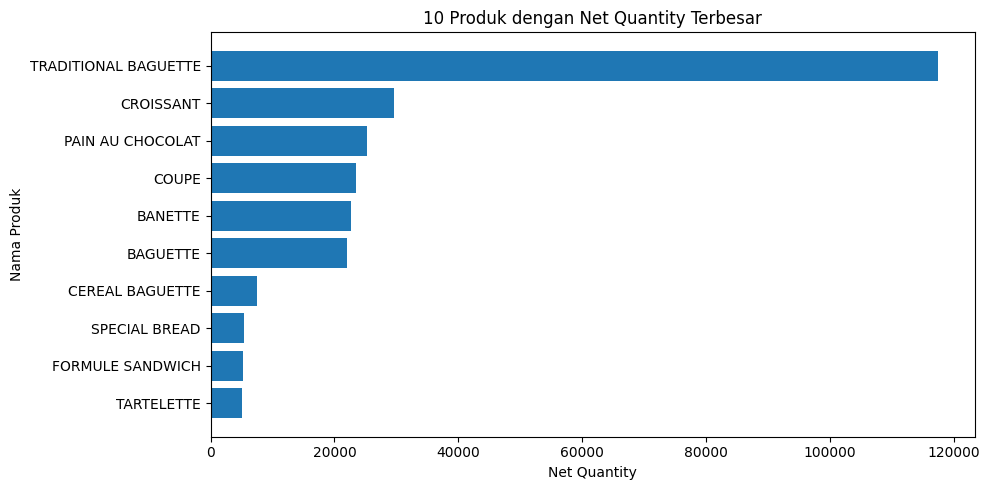

In [ ]:

# CELL 12 : Membuat grafik 10 produk teratas

# Ambil 10 produk dengan net Quantity terbesar
top_10 = total_quantity.head(10)

# Membuat grafik batang
plt.figure(figsize=(10, 5))
plt.barh(top_10.index, top_10.values)

plt.title("10 Produk dengan Net Quantity Terbesar")
plt.xlabel("Net Quantity")
plt.ylabel("Nama Produk")

# Produk dengan nilai terbesar tampil di bagian atas
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


In [ ]:

# CELL 13 : Transaksi negatif

# 1. Pisahkan transaksi negatif dan positif
data_negatif = df_clean[df_clean["Quantity"] < 0]
data_positif = df_clean[df_clean["Quantity"] > 0]

print("Jumlah baris negatif:", len(data_negatif))
print("Total Quantity negatif:", data_negatif["Quantity"].sum())

print("\nJumlah baris positif:", len(data_positif))
print("Total Quantity positif:", data_positif["Quantity"].sum())

# 2. Jumlahkan Quantity berdasarkan tanggal dan produk
cek_harian = (
    df_clean.groupby(["date", "article"])["Quantity"]
    .sum()
    .reset_index()
)

# 3. Cari kombinasi tanggal dan produk dengan hasil negatif
hasil_negatif = cek_harian[cek_harian["Quantity"] < 0]

print("\nKombinasi tanggal dan produk dengan net Quantity negatif:",
      len(hasil_negatif))

display(hasil_negatif.head(10))


Jumlah baris negatif: 1295
Total Quantity negatif: -2201.0

Jumlah baris positif: 232710
Total Quantity positif: 362189.0

Kombinasi tanggal dan produk dengan net Quantity negatif: 0


,date,article,Quantity


Baris transaksi negatif :1.295

Total Quantity negatif : −2.201


Baris transaksi positif :232.710

Total Quantity positif : 362.189

Tanggal–produk dengan net negatif :0


In [ ]:
# CELL 14 : Memeriksa nama produk
print("==== Jumlah nama produk berbeda sebelum filter====")
print(df_clean["article"].nunique())

print("\n==== Nama produk yang mengandung DIVERS====")
produk_divers = df_clean[
    df_clean["article"].str.contains("DIVERS", na=False)
]["article"].value_counts()

display(produk_divers)

print("\n====Nama produk yang paling sering muncul====")
display(df_clean["article"].value_counts().head(20))


==== Jumlah nama produk berbeda sebelum filter====
149

==== Nama produk yang mengandung DIVERS====


,count
article,
DIVERS VIENNOISERIE,827
DIVERS PATISSERIE,500
DIVERS CONFISERIE,482
DIVERS BOULANGERIE,316
DIVERS SANDWICHS,239
DIVERS BOISSONS,85



====Nama produk yang paling sering muncul====


,count
article,
TRADITIONAL BAGUETTE,67689
COUPE,20470
BAGUETTE,15292
BANETTE,15130
CROISSANT,11508
PAIN AU CHOCOLAT,10578
SPECIAL BREAD,5195
CEREAL BAGUETTE,4961
FORMULE SANDWICH,4202


In [ ]:

# CELL 15 : Filter produk dan ranking

# 1. Buang nama produk tidak valid dan kategori DIVERS
mask_valid = (
    df_clean["article"].astype(str).str.contains(
        r"[A-Za-z0-9]", regex=True
    )
    & ~df_clean["article"].str.contains(
        "DIVERS", case=False, na=False
    )
)

df_clean = df_clean[mask_valid].copy()

print("Baris sebelum filter:", len(df))
print("Baris setelah filter :", len(df_clean))

# 2. Bagi data berdasarkan waktu
SPLIT_DATE = pd.Timestamp("2022-06-01")

train = df_clean[df_clean["date"] < SPLIT_DATE]
test = df_clean[df_clean["date"] >= SPLIT_DATE]

print("\nPeriode train:")
print(train["date"].min(), "sampai", train["date"].max())

print("\nPeriode test:")
print(test["date"].min(), "sampai", test["date"].max())

print("\nJumlah hari train:", train["date"].nunique())
print("Jumlah hari test :", test["date"].nunique())

# 3. Ranking produk hanya berdasarkan periode train
top = (
    train.groupby("article")
    .agg(
        total_qty=("Quantity", "sum"),
        n_hari=("date", "nunique")
    )
    .sort_values("total_qty", ascending=False)
)

print("\n15 ==== Produk teratas pada periode train====")
display(top.head(15))


Baris sebelum filter: 234005
Baris setelah filter : 231551

Periode train:
2021-01-02 00:00:00 sampai 2022-05-31 00:00:00

Periode test:
2022-06-01 00:00:00 sampai 2022-09-30 00:00:00

Jumlah hari train: 480
Jumlah hari test : 120

15 ==== Produk teratas pada periode train====


,total_qty,n_hari
article,,
TRADITIONAL BAGUETTE,85433.0,480
CROISSANT,21546.0,479
PAIN AU CHOCOLAT,18439.0,478
COUPE,17815.0,480
BANETTE,17147.0,480
BAGUETTE,16915.0,480
CEREAL BAGUETTE,5933.0,479
SPECIAL BREAD,4162.0,478
FORMULE SANDWICH,4047.0,429


**Bagian 1 : Filter produk**
> Kita mempertahankan produk dengan nama yang mengandung huruf atau angka, lalu mengecualikan nama yang mengandung DIVERS.



**Bagian 2 : Membagi waktu**
  > **Train** :
  2 Januari 2021 - 31 Mei 2022
  Digunakan untuk menentukan ranking kandidat produk.

  

  > **Test** :
  1 Juni - 30 September 2022
  Periode waktu yang disisihkan untuk evaluasi pada tahap berikutnya.




In [ ]:
# Cell 16 : Cek harga dan cakupan hari penjualan


#1. Periksa harga 6 kandidat produk
cek_produk = ["COUPE" , "TRADITIONAL BAGUETTE","CROISSANT","PAIN AU CHOCOLAT","BANETTE","BAGUETTE"]
print("Harga yang tercatat untuk setiap produk")

harga_produk=(df_clean[df_clean["article"].isin(cek_produk)]
              .groupby("article")["unit_price"].unique())
display(harga_produk)

#2. Hitung berapa hari setiap produk muncul pada periode train
hari_jual =(train.groupby("article")["date"].nunique())
total_hari = train["date"].nunique()

# 3. Ringkas total Quantity dan cakupan hari
ringkas = (train.groupby("article")["Quantity"].sum().rename("total_qty").to_frame())
ringkas["hari_ada_penjualan"] = hari_jual
ringkas = ringkas.sort_values("total_qty",ascending=False).head(10)
ringkas["pct_hari"] = (ringkas["hari_ada_penjualan"] / total_hari *100 ).round(1)

print("\nTotal hari train:", total_hari)
print("\n==== Ringkasan 10 produk teratas : ")
display(ringkas)




Harga yang tercatat untuk setiap produk


,unit_price
article,
BAGUETTE,"[0.9, 0.95, 1.0]"
BANETTE,"[1.05, 1.1, 1.15]"
COUPE,[0.15]
CROISSANT,"[1.1, 1.15, 1.2]"
PAIN AU CHOCOLAT,"[1.2, 1.25, 1.3]"
TRADITIONAL BAGUETTE,"[1.2, 1.25, 1.3]"



Total hari train: 480

==== Ringkasan 10 produk teratas : 


,total_qty,hari_ada_penjualan,pct_hari
article,,,
TRADITIONAL BAGUETTE,85433.0,480,100.0
CROISSANT,21546.0,479,99.8
PAIN AU CHOCOLAT,18439.0,478,99.6
COUPE,17815.0,480,100.0
BANETTE,17147.0,480,100.0
BAGUETTE,16915.0,480,100.0
CEREAL BAGUETTE,5933.0,479,99.8
SPECIAL BREAD,4162.0,478,99.6
FORMULE SANDWICH,4047.0,429,89.4


Menentukan produk yang digunakan dalam simulasi

In [ ]:
# Cell 17 : Menetapkan produk untuk simulasi

selected_products = ['TRADITIONAL BAGUETTE','CROISSANT','PAIN AU CHOCOLAT','BANETTE','BAGUETTE']

print("==== Produk yang digunakan dalam simulasi ====")

for produk in selected_products:
  print("-",produk)

==== Produk yang digunakan dalam simulasi ====
- TRADITIONAL BAGUETTE
- CROISSANT
- PAIN AU CHOCOLAT
- BANETTE
- BAGUETTE


Menghitunga Penjualan harian setiap produk

In [ ]:
# Cell 18 : Agregasi penjualan harian setiap produk

sales_selected = df_clean[df_clean["article"].isin(selected_products)].copy()
daily_sales = (sales_selected.groupby(["date","article"])["Quantity"].sum().reset_index())

print("Jumlah baris transaksi untuk 5 produk :", len(sales_selected))
print("Jumlah baris hasil agregasi harian :", len(daily_sales))

print("\n==== Contoh hasil agregasi harian====")
display(daily_sales.head(10))

Jumlah baris transaksi untuk 5 produk : 120197
Jumlah baris hasil agregasi harian : 2997

==== Contoh hasil agregasi harian====


,date,article,Quantity
0,2021-01-02,BAGUETTE,46.0
1,2021-01-02,BANETTE,40.0
2,2021-01-02,CROISSANT,66.0
3,2021-01-02,PAIN AU CHOCOLAT,48.0
4,2021-01-02,TRADITIONAL BAGUETTE,128.0
5,2021-01-03,BAGUETTE,35.0
6,2021-01-03,BANETTE,35.0
7,2021-01-03,CROISSANT,59.0
8,2021-01-03,PAIN AU CHOCOLAT,45.0
9,2021-01-03,TRADITIONAL BAGUETTE,171.0


In [ ]:
# Cell 19 : Cek tanggal tanpa transa=ksu

# Buat rentang seluruh tanggal dari awal hingga akhir
full_range = pd.date_range(
    daily_sales["date"].min(),
    daily_sales["date"].max(),
    freq="D"
)

# ambil tanggal yang muncul dalam hasil agregasi
tanggal_ada = daily_sales["date"].unique()

#cari tanggal kalender yang tiak memiliki transaksi
tanggal_kosong = full_range.difference(tanggal_ada)



print("Jumlah hari kalender :", len(full_range))
print("Hari dengan transaksi :", len(tanggal_ada))
print("Hari tanpa transaksi :", len(tanggal_kosong))

print("\n==== Contoh tanggal tanpa transaksi====")
display(pd.DataFrame({"date":tanggal_kosong[:15]}))

Jumlah hari kalender : 637
Hari dengan transaksi : 600
Hari tanpa transaksi : 37

==== Contoh tanggal tanpa transaksi====


,date
0,2021-01-06
1,2021-01-13
2,2021-01-20
3,2021-01-27
4,2021-02-03
5,2021-02-10
6,2021-02-17
7,2021-02-24
8,2021-03-03
9,2021-03-10


> Catatan penting: tanggal tanpa transaksi lima produk belum tentu hari toko tutup. Bisa saja kelima produk tersebut tidak tercatat terjual pada tanggal itu. informasi ini  membuat asumsi kalender, jadi kita perlu memahami keterbatasannya sebelum menggunakannya dalam simulasi stok.

Rentang kalender : 637 hari |
Ada transaksi : 600 hari |
Tanpa transaksi : 37 hari


> 37 hari tanpa transaksi adalah sekitar 5,8% dari seluruh rentang kalender.





In [ ]:
# Cell 20 :Membuat kalender hasian lengkap

#1. Buat tanggal dalam rentang dataset
tanggal_lengkap = pd.date_range(start=daily_sales["date"].min(),
                                end=daily_sales["date"].max(),
                                freq="D")

#2. Buat semua kombinasi tanggal dan 5 produk
kalender = pd.MultiIndex.from_product([tanggal_lengkap, selected_products], names=["date", "article"]).to_frame(index=False)

#3. Gabungkan kalender dengan hasil penjualan harian
daily_sales_full = kalender.merge(daily_sales, on=["date","article"], how="left")

#4. isi kombinasi tanpa transaksi dengan quantity 0
daily_sales_full["Quantity"] = (daily_sales_full["Quantity"].fillna(0))


#5. hasil
print("Jumlah tanggal:", len(tanggal_lengkap))
print("Jumlah produk: ", len(selected_products))
print("Jumlah baris seharusnya:" , len(tanggal_lengkap) * len(selected_products))
print("Jumlah baris aktual :",len(daily_sales_full))
print("\n====Contoh hasil kalender lengkap====")
display(daily_sales_full.head(10))

Jumlah tanggal: 637
Jumlah produk:  5
Jumlah baris seharusnya: 3185
Jumlah baris aktual : 3185

====Contoh hasil kalender lengkap====


,date,article,Quantity
0,2021-01-02,TRADITIONAL BAGUETTE,128.0
1,2021-01-02,CROISSANT,66.0
2,2021-01-02,PAIN AU CHOCOLAT,48.0
3,2021-01-02,BANETTE,40.0
4,2021-01-02,BAGUETTE,46.0
5,2021-01-03,TRADITIONAL BAGUETTE,171.0
6,2021-01-03,CROISSANT,59.0
7,2021-01-03,PAIN AU CHOCOLAT,45.0
8,2021-01-03,BANETTE,35.0
9,2021-01-03,BAGUETTE,35.0


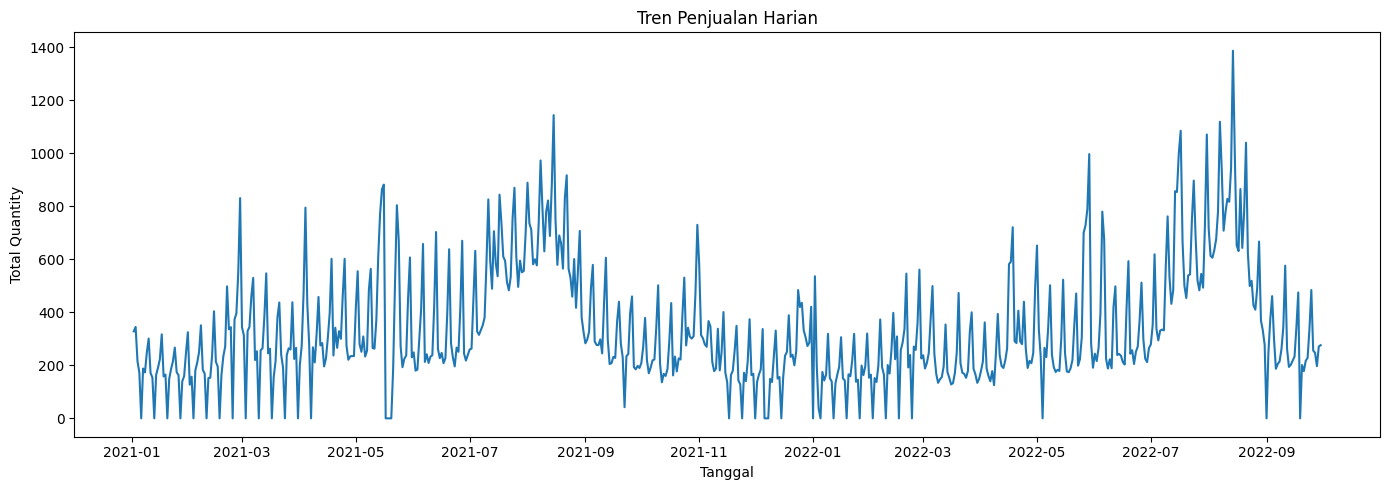

In [ ]:
# Cell 21:Analisis Tren Penjualan

# Jumlahkan Quantity 5 produk pada setiap tanggal
total_harian = (daily_sales_full.groupby("date")["Quantity"].sum())

# Grafik Tren
plt.figure(figsize=(14,5))
plt.plot(total_harian.index, total_harian.values)
plt.title("Tren Penjualan Harian")
plt.xlabel("Tanggal")
plt.ylabel("Total Quantity")
plt.tight_layout()
plt.show()


Dari grafik pertama, ada beberapa hal yang terlihat:
> Penjualan berfluktuasi setiap hari. Total Quantity naik dan turun secara tajam, sehingga penjualan tidak selalu stabil.

> Ada lonjakan penjualan pada beberapa periode, terutama sekitar Juli–Agustus 2021 dan Juli–Agustus 2022.

> Terdapat beberapa hari dengan nilai nol. Karena grafik menggunakan kalender lengkap, nilai nol berarti tidak ada net transaksi tercatat untuk lima produk tersebut pada tanggal itu. Ini tidak otomatis berarti toko tutup.

> Pola penjualan berbeda sepanjang periode pengamatan. Ini menjadi alasan mengapa kebutuhan bahan baku sebaiknya dihitung berdasarkan tanggal, bukan hanya menggunakan rata-rata keseluruhan.

==== Rata-rata net quantity berdasarkan hari ====


,Quantity
hari,
Monday,319.538462
Tuesday,268.000000
Wednesday,206.373626
Thursday,291.439560
Friday,301.307692
Saturday,419.098901
Sunday,580.373626


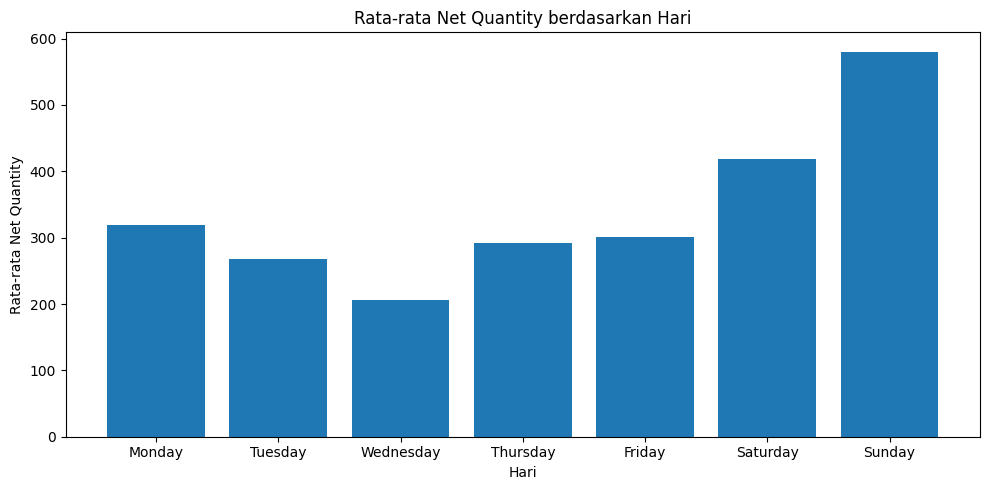

In [ ]:
# Cell 22: Tren penjualan mingguan

# buat kolom nama hari
total_harian_df = total_harian.reset_index()
total_harian_df["hari"] = (total_harian_df["date"].dt.day_name())

#urutan hari agar grafik tidak alfabetis
urutan_hari = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
# Hitung rata-rata Quantity untuk setiap hari
rata_harian = (total_harian_df.groupby("hari")["Quantity"].mean().reindex(urutan_hari))


print("==== Rata-rata net quantity berdasarkan hari ====")
display(rata_harian)

plt.figure(figsize=(10,5))

plt.bar(rata_harian.index, rata_harian.values)
plt.title("Rata-rata Net Quantity berdasarkan Hari")
plt.xlabel("Hari")
plt.ylabel("Rata-rata Net Quantity")
plt.tight_layout()
plt.show()

* Minggu memiliki rata-rata tertinggi, sekitar 580,37 unit.
* Sabtu berada di urutan kedua, sekitar 419,10 unit.
* Rabu memiliki rata-rata terendah, sekitar 206,37 unit.

> Secara umum, penjualan akhir pekan lebih tinggi daripada hari kerja dalam data yang dianalisis.

# Pemetaan resep dan bahan baku


>Menentukan bahan apa saja yang dibutuhkan untuk membuat setiap produk serta jumlah bahan per unit produk.

In [ ]:
# Cell 23 : Memeriksa variable yang sudah tersedia

print("==== Produk terpilih ====")
print(selected_products)
print("\n==== Data penjualan harian lengka ====")
print(daily_sales_full.shape)
print("\n==== data top 5 ====")
display(daily_sales_full.head())

==== Produk terpilih ====
['TRADITIONAL BAGUETTE', 'CROISSANT', 'PAIN AU CHOCOLAT', 'BANETTE', 'BAGUETTE']

==== Data penjualan harian lengka ====
(3185, 3)

==== data top 5 ====


,date,article,Quantity
0,2021-01-02,TRADITIONAL BAGUETTE,128.0
1,2021-01-02,CROISSANT,66.0
2,2021-01-02,PAIN AU CHOCOLAT,48.0
3,2021-01-02,BANETTE,40.0
4,2021-01-02,BAGUETTE,46.0


#Pemetaan Resep Produk

In [ ]:
# CELL 24 — Memeriksa variabel pemetaan resep

# 1. Pemetaan produk dataset ke produk simulasi Tewiwi
MAPPING = {
    "TRADITIONAL BAGUETTE": "country_bread",
    "CROISSANT": "blueberry_crumble",
    "PAIN AU CHOCOLAT": "dusty_choco",
    "BANETTE": "shokupan",
    "BAGUETTE": "salt_bread",
}

# 2. Resep: pemakaian bahan per 1 unit produk
RESEP = {
    "country_bread": {
        "terigu_protein_tinggi": 265,
        "tepung_gandum_utuh": 65,
        "garam": 7,
    },
    "salt_bread": {
        "terigu_protein_tinggi": 50,
        "ragi_instan": 1,
        "garam": 1,
        "gula": 3,
        "mentega": 20,
    },
    "dusty_choco": {
        "terigu_protein_tinggi": 120,
        "ragi_instan": 2,
        "garam": 2,
        "gula": 25,
        "mentega": 15,
        "telur": 0.15,
        "cokelat": 40,
    },
    "shokupan": {
        "terigu_protein_tinggi": 250,
        "garam": 5,
        "gula": 20,
        "mentega": 25,
        "susu_bubuk": 10,
        "telur": 0.2,
    },
    "blueberry_crumble": {
        "terigu_protein_tinggi": 70,
        "ragi_instan": 1.5,
        "garam": 1.5,
        "gula": 15,
        "mentega": 10,
        "susu_bubuk": 5,
        "telur": 0.1,
        "cream_cheese": 30,
    },
}

# 3. Ubah resep menjadi DataFrame
resep_df = (
    pd.DataFrame(RESEP)
    .fillna(0)
    .stack()
    .rename("qty_per_unit")
    .reset_index()
    .rename(columns={
        "level_0": "bahan",
        "level_1": "produk"
    })
)

resep_df = resep_df[resep_df["qty_per_unit"] > 0].copy()

print("Jumlah bahan:", resep_df["bahan"].nunique())
display(resep_df.head())

# 4. Gunakan data penjualan harian lengkap
d = daily_sales_full.copy()

# Samakan nama kolom dengan notebook lama
d = d.rename(columns={"Quantity": "qty"})

# Petakan produk dataset ke produk simulasi
d["produk"] = d["article"].map(MAPPING)

# 5. Hitung estimasi pemakaian bahan baku
usage = (
    d.merge(resep_df, on="produk", how="inner")
    .assign(
        usage=lambda x: x["qty"] * x["qty_per_unit"]
    )
    .groupby(["date", "bahan"], as_index=False)["usage"]
    .sum()
)

print("\nShape usage:", usage.shape)
print("Target jumlah baris:", 637 * 10)

print("\nContoh pemakaian bahan pada 2 Januari 2021:")
display(usage[usage["date"] == "2021-01-02"])

Jumlah bahan: 10


,bahan,produk,qty_per_unit
0,terigu_protein_tinggi,country_bread,265.0
1,terigu_protein_tinggi,salt_bread,50.0
2,terigu_protein_tinggi,dusty_choco,120.0
3,terigu_protein_tinggi,shokupan,250.0
4,terigu_protein_tinggi,blueberry_crumble,70.0



Shape usage: (6370, 3)
Target jumlah baris: 6370

Contoh pemakaian bahan pada 2 Januari 2021:


,date,bahan,usage
0,2021-01-02,cokelat,1920.0
1,2021-01-02,cream_cheese,1980.0
2,2021-01-02,garam,1337.0
3,2021-01-02,gula,3128.0
4,2021-01-02,mentega,3300.0
5,2021-01-02,ragi_instan,241.0
6,2021-01-02,susu_bubuk,730.0
7,2021-01-02,telur,21.8
8,2021-01-02,tepung_gandum_utuh,8320.0
9,2021-01-02,terigu_protein_tinggi,56600.0


In [ ]:
# CELL 25 — Simpan data hasil konversi

usage.to_csv(PROCESSED_DIR / "usage_harian.csv", index=False)

print("Tersimpan:", PROCESSED_DIR /"usage_harian.csv")

Tersimpan: /content/drive/MyDrive/Tewiwi-Bakehouse/data/processed/usage_harian.csv


#Parameter Simulasi Inventory & Penentuan Hari Bulk Order

> Sebelum bisa mensimulasikan stok harian, kita perlu dua hal dulu: (1) aturan main simulasinya (berapa lama barang datang setelah dipesan, kapan harus pesan ulang, berapa buffer amannya), dan (2) tentukan hari-hari mana yang mengalami bulk order (lonjakan pesanan besar). Karena ini persis masalah yang disebutkan di Problem Statement project plan: “ketika terdapat bulk order maka kebutuhan akan bahan berubah cukup signifikan dalam waktu singkat.”

In [ ]:
# CELL 26a : Eksplorasi pesanan besar dari data transaksi aktual

# 1. Ambil transaksi 5 produk terpilih, hanya pembelian (Quantity positif)
trx = df_clean[
    (df_clean["article"].isin(selected_products)) & (df_clean["Quantity"] > 0)
].copy()

# 2. Jumlahkan quantity per tiket per produk (1 tiket = 1 transaksi pelanggan)
per_tiket = (
    trx.groupby(["date", "ticket_number", "article"])["Quantity"]
    .sum()
    .reset_index()
)

print("Jumlah baris tiket-produk:", len(per_tiket))

# 3. Sebaran quantity per tiket untuk tiap produk
print("\n==== Sebaran quantity per tiket ====")
display(
    per_tiket.groupby("article")["Quantity"]
    .describe(percentiles=[0.5, 0.9, 0.99, 0.999])
    .round(1)
)

# 4. Tiket dengan quantity terbesar
print("\n==== 15 tiket dengan quantity terbesar ====")
display(per_tiket.sort_values("Quantity", ascending=False).head(15))

Jumlah baris tiket-produk: 119266

==== Sebaran quantity per tiket ====


,count,mean,std,min,50%,90%,99%,99.9%,max
article,,,,,,,,,
BAGUETTE,15207.0,1.5,1.1,1.0,1.0,2.0,5.0,10.0,43.0
BANETTE,14997.0,1.5,1.0,1.0,1.0,3.0,5.0,8.0,20.0
CROISSANT,11387.0,2.6,1.9,1.0,2.0,5.0,10.0,15.6,25.0
PAIN AU CHOCOLAT,10479.0,2.4,1.7,1.0,2.0,5.0,9.0,15.0,25.0
TRADITIONAL BAGUETTE,67196.0,1.8,1.2,1.0,1.0,3.0,6.0,10.0,55.0



==== 15 tiket dengan quantity terbesar ====


,date,ticket_number,article,Quantity
58431,2021-10-31,217821.0,TRADITIONAL BAGUETTE,55.0
59995,2021-11-08,219600.0,BAGUETTE,43.0
45378,2021-08-22,202518.0,CROISSANT,25.0
45379,2021-08-22,202518.0,PAIN AU CHOCOLAT,25.0
56189,2021-10-19,215345.0,TRADITIONAL BAGUETTE,25.0
60104,2021-11-09,219760.0,BAGUETTE,25.0
114706,2022-09-03,283514.0,BANETTE,20.0
31976,2021-07-14,187952.0,TRADITIONAL BAGUETTE,20.0
11419,2021-03-29,163761.0,BAGUETTE,20.0
95897,2022-07-10,263296.0,CROISSANT,20.0


In [ ]:
# CELL 26a (lanjutan) : Bandingkan definisi bulk order

train_tiket = per_tiket[per_tiket["date"] < SPLIT_DATE]

# =========================================================
# Pilihan A: tiket besar (satu transaksi dengan quantity tinggi)
# =========================================================
print("==== Pilihan A: tiket besar ====")
for q in [0.99, 0.999]:
    batas = train_tiket.groupby("article")["Quantity"].quantile(q)
    flag = per_tiket["Quantity"] > per_tiket["article"].map(batas)
    print(f"Persentil {q}: {flag.sum()} tiket, terjadi di {per_tiket.loc[flag, 'date'].nunique()} hari")

# Seberapa besar tiket terbesar dibanding penjualan produk itu di hari yang sama
harian = daily_sales.rename(columns={"Quantity": "qty_hari"})
porsi = per_tiket.merge(harian, on=["date", "article"])
porsi["porsi_dari_harian"] = (porsi["Quantity"] / porsi["qty_hari"] * 100).round(1)

print("\n10 tiket terbesar dan porsinya terhadap penjualan hari itu (%):")
display(
    porsi.sort_values("Quantity", ascending=False)
    [["date", "article", "Quantity", "qty_hari", "porsi_dari_harian"]]
    .head(10)
)

# =========================================================
# Pilihan B: lonjakan harian dibanding hari yang sama dalam seminggu
# =========================================================
print("\n==== Pilihan B: lonjakan harian ====")
harian_cek = daily_sales_full.copy()
harian_cek["dow"] = harian_cek["date"].dt.dayofweek

# Batas per produk per hari dalam seminggu, dari periode train dan hari ada penjualan
batas_hari = (
    harian_cek[(harian_cek["date"] < SPLIT_DATE) & (harian_cek["Quantity"] > 0)]
    .groupby(["article", "dow"])["Quantity"]
    .quantile(0.95)
    .rename("batas")
    .reset_index()
)
harian_cek = harian_cek.merge(batas_hari, on=["article", "dow"], how="left")
harian_cek["lonjakan"] = harian_cek["Quantity"] > harian_cek["batas"]

print("Jumlah kejadian lonjakan (produk-hari):", harian_cek["lonjakan"].sum())
print("Jumlah hari dengan minimal 1 lonjakan:", harian_cek.loc[harian_cek["lonjakan"], "date"].nunique())

harian_cek["kali_batas"] = (harian_cek["Quantity"] / harian_cek["batas"]).round(2)
print("\nContoh lonjakan terbesar:")
display(
    harian_cek[harian_cek["lonjakan"]]
    .sort_values("kali_batas", ascending=False)
    [["date", "article", "Quantity", "batas", "kali_batas"]]
    .head(10)
)

# =========================================================
# Sebaran kejadian di periode train dan test
# =========================================================
print("\n==== Sebaran hari bulk di periode train dan test ====")
batas_999 = train_tiket.groupby("article")["Quantity"].quantile(0.999)
flag_A = per_tiket["Quantity"] > per_tiket["article"].map(batas_999)

hari_A = pd.Series(per_tiket.loc[flag_A, "date"].unique())
hari_B = pd.Series(harian_cek.loc[harian_cek["lonjakan"], "date"].unique())

# Pembanding: hari buka di train dan test (tanggal_ada dari Cell 19)
hari_buka_all = pd.Series(tanggal_ada)
n_buka_train = (hari_buka_all < SPLIT_DATE).sum()
n_buka_test = (hari_buka_all >= SPLIT_DATE).sum()
print(f"Hari buka: train {n_buka_train}, test {n_buka_test}\n")

for nama, h in [("A: tiket p99.9", hari_A), ("B: lonjakan harian", hari_B)]:
    n_train = (h < SPLIT_DATE).sum()
    n_test = (h >= SPLIT_DATE).sum()
    print(
        f"{nama:20s} | train: {n_train:3d} hari ({n_train / n_buka_train * 100:.1f}% hari buka train)"
        f" | test: {n_test:3d} hari ({n_test / n_buka_test * 100:.1f}% hari buka test)"
    )

==== Pilihan A: tiket besar ====
Persentil 0.99: 886 tiket, terjadi di 412 hari
Persentil 0.999: 74 tiket, terjadi di 64 hari

10 tiket terbesar dan porsinya terhadap penjualan hari itu (%):


,date,article,Quantity,qty_hari,porsi_dari_harian
58431,2021-10-31,TRADITIONAL BAGUETTE,55.0,369.0,14.9
59995,2021-11-08,BAGUETTE,43.0,62.0,69.4
45378,2021-08-22,CROISSANT,25.0,144.0,17.4
45379,2021-08-22,PAIN AU CHOCOLAT,25.0,154.0,16.2
56189,2021-10-19,TRADITIONAL BAGUETTE,25.0,143.0,17.5
60104,2021-11-09,BAGUETTE,25.0,43.0,58.1
114706,2022-09-03,BANETTE,20.0,43.0,46.5
31976,2021-07-14,TRADITIONAL BAGUETTE,20.0,403.0,5.0
11419,2021-03-29,BAGUETTE,20.0,45.0,44.4
95897,2022-07-10,CROISSANT,20.0,127.0,15.7



==== Pilihan B: lonjakan harian ====
Jumlah kejadian lonjakan (produk-hari): 237
Jumlah hari dengan minimal 1 lonjakan: 97

Contoh lonjakan terbesar:


,date,article,Quantity,batas,kali_batas
2931,2022-08-11,CROISSANT,147.0,73.40,2.00
2796,2022-07-15,CROISSANT,153.0,77.40,1.98
2551,2022-05-27,CROISSANT,139.0,77.40,1.80
2791,2022-07-14,CROISSANT,131.0,73.40,1.78
2797,2022-07-15,PAIN AU CHOCOLAT,131.0,74.00,1.77
1067,2021-08-03,PAIN AU CHOCOLAT,96.0,55.15,1.74
2947,2022-08-14,PAIN AU CHOCOLAT,232.0,138.80,1.67
2936,2022-08-12,CROISSANT,128.0,77.40,1.65
2950,2022-08-15,TRADITIONAL BAGUETTE,585.0,357.90,1.63
2966,2022-08-18,CROISSANT,120.0,73.40,1.63



==== Sebaran hari bulk di periode train dan test ====
Hari buka: train 480, test 120

A: tiket p99.9       | train:  45 hari (9.4% hari buka train) | test:  19 hari (15.8% hari buka test)
B: lonjakan harian   | train:  56 hari (11.7% hari buka train) | test:  41 hari (34.2% hari buka test)


In [ ]:
# CELL 26 : Parameter simulasi dan penandaan bulk order dari data aktual

SEED       = 42     # tetap disimpan untuk model di notebook berikutnya
WASTE_PCT  = 0.05   # wawancara: waste 5-10%, maksimal 10%
LEAD_TIME  = 3      # wawancara + jurnal: pengiriman 1-3 hari
ORDER_DAYS = 7      # wawancara + jurnal: belanja mingguan
INIT_DAYS  = 6      # stok awal = rata-rata pemakaian x 6 hari
SERVICE_Z  = 1.65   # tingkat layanan 95% untuk safety stock (dipakai di Cell 26b)
BULK_Q     = 0.999  # tiket di atas persentil 99,9 per produk (Cell 26a: 64 hari, sekitar 11% hari buka)

# 1. Daftar tanggal dan penanda hari toko buka
tanggal = sorted(usage["date"].unique())
is_open = pd.Series(1, index=tanggal)
is_open[~is_open.index.isin(tanggal_ada)] = 0
print("Jumlah hari toko buka:", is_open.sum(), "dari", len(tanggal), "hari")

# 2. Batas bulk per produk, dihitung HANYA dari periode train
#    (per_tiket dibuat di Cell 26a)
batas_bulk = (
    per_tiket[per_tiket["date"] < SPLIT_DATE]
    .groupby("article")["Quantity"]
    .quantile(BULK_Q)
)
print("\n==== Batas bulk order per produk (quantity per tiket) ====")
print(batas_bulk)

# 3. Tandai tiket yang melebihi batas produknya
per_tiket["is_bulk_tiket"] = per_tiket["Quantity"] > per_tiket["article"].map(batas_bulk)

# 4. Ambil kombinasi tanggal dan produk yang punya tiket bulk
bulk_produk = per_tiket.loc[per_tiket["is_bulk_tiket"], ["date", "article"]].drop_duplicates()
bulk_produk["produk"] = bulk_produk["article"].map(MAPPING)

# 5. Ubah ke level bahan lewat resep: hanya bahan dari produk itu yang ditandai
bulk_bahan = (
    bulk_produk.merge(resep_df[["produk", "bahan"]], on="produk")
    [["date", "bahan"]]
    .drop_duplicates()
)
bulk_set = set(zip(pd.to_datetime(bulk_bahan["date"]), bulk_bahan["bahan"]))

print("\nJumlah tiket bulk:", per_tiket["is_bulk_tiket"].sum())
print("Jumlah hari dengan minimal 1 tiket bulk:", bulk_produk["date"].nunique())
print("\n==== Tiket bulk per produk ====")
print(per_tiket.groupby("article")["is_bulk_tiket"].sum())

Jumlah hari toko buka: 600 dari 637 hari

==== Batas bulk order per produk (quantity per tiket) ====
article
BAGUETTE                10.000
BANETTE                  8.000
CROISSANT               16.701
PAIN AU CHOCOLAT        15.000
TRADITIONAL BAGUETTE    10.000
Name: Quantity, dtype: float64

Jumlah tiket bulk: 74
Jumlah hari dengan minimal 1 tiket bulk: 64

==== Tiket bulk per produk ====
article
BAGUETTE                11
BANETTE                 11
CROISSANT               11
PAIN AU CHOCOLAT         8
TRADITIONAL BAGUETTE    33
Name: is_bulk_tiket, dtype: int64


In [ ]:
# CELL 26b : Safety stock statistik per bahan

# 1. Ambil pemakaian periode train saja, dan hanya hari toko buka
#    (hari tutup bernilai 0 akan membuat naik-turunnya terlihat lebih besar dari aslinya)
hari_buka = is_open[is_open == 1].index
u_train = usage[(usage["date"] < SPLIT_DATE) & (usage["date"].isin(hari_buka))]

# 2. Rata-rata dan simpangan baku pemakaian harian per bahan
stat = u_train.groupby("bahan")["usage"].agg(rata2="mean", std="std")

# 3. CV: seberapa naik turun pemakaian dibanding rata-ratanya
stat["cv"] = stat["std"] / stat["rata2"]

# 4. Safety stock dalam satuan hari
stat["safety_days"] = SERVICE_Z * stat["cv"] * np.sqrt(LEAD_TIME)

# 5. Titik pesan ulang dalam satuan hari (rumus mentor)
stat["rop_days"] = LEAD_TIME + stat["safety_days"]

# 6. Simpan sebagai dictionary untuk dipakai di Cell 27
SAFETY_DAYS = stat["safety_days"].to_dict()

print("==== Safety stock dan ROP per bahan (dalam hari) ====")
display(stat[["cv", "safety_days", "rop_days"]].round(2).sort_values("safety_days"))

==== Safety stock dan ROP per bahan (dalam hari) ====


,cv,safety_days,rop_days
bahan,,,
mentega,0.55,1.58,4.58
garam,0.56,1.61,4.61
terigu_protein_tinggi,0.56,1.61,4.61
tepung_gandum_utuh,0.57,1.64,4.64
susu_bubuk,0.59,1.68,4.68
telur,0.61,1.76,4.76
gula,0.63,1.80,4.80
ragi_instan,0.66,1.89,4.89
cokelat,0.71,2.04,5.04


Secara konsep Inventory, reorder point biasanya dihitung sebagai:
ROP = Demand lead time + Safety Stock

Jika, demand dianggap konstan:
ROP = Average Daily Demand * Lead time + safety stock

Jika safety stock ditetapkan dalam satuan hari:
ROP = Average Daily Demand * (lead time + safety stock)


rumus yang digunakan sudah sesuai tetapi ada hal lain yang perlu dinotes: apakah asumsi 2 hari lead time dan 2 hari safety stock benar-benar sesuai dengan operasional yg sesungguhnya





Terait penentuan bulk order

1. Bulk Order belum berdasarkan data aktual
Saat ini, bulk order terjadi hanya karena random number. Bulk order harus ditentukan idelanya menggunakan data pesanan aktual

2. Bahan baku jangan semuanya dinaikin, tapi naikin aja yg memang dipakai untuk bulk order

In [ ]:
# Cell 27 : Loop simulasi stok harian per bahan


#1. ubah data pemakaian dari format(date,bahan, usage)
# keformat lebar baris=tanggal , kolom= nama bahan
u = usage.pivot(index="date", columns="bahan", values="usage").sort_index()



#2. Rata-rata pemakaian tiap bahan, dihitung hanya dari hari toko buka
# dipakai sebagai patokan menentukan stok awal
mask_buka = is_open.loc[u.index].values==1
avg_all = u[mask_buka].mean() * ( 1 + WASTE_PCT)

hasil = []

for bahan in u.columns:
  demand = u[bahan].values
  stok = avg_all[bahan]* INIT_DAYS
  pipeline = {}         # {hari_ke-berapa datang: jumlah yang dipesan}

  for i, tgl in enumerate(u.index):
    # a. Barang yang dipesan sebelumnya, kalau sudah waktunya datang hari ini
    masuk = pipeline.pop(i, 0.0)
    stok += masuk

    #b. kebutuhan hari ini (ditambah 5% waste) dipenuhi semaksimal stok yang ada
    butuh = demand[i]*(1 + WASTE_PCT)
    pakai = min(butuh, stok)
    shortage = butuh - pakai
    stok -= pakai

    #c. rata-rata pemakaian 30 hari terakhir saja ( tidak mengintip masa depan)
    awal = max(0, i-30)
    window = demand[awal:i] * (1 + WASTE_PCT) #menghitung juga untuk bahan yang terbuang
    window = window[window > 0]
    avg30 = window.mean() if len(window) > 0 else avg_all[bahan]

    ss_days = SAFETY_DAYS[bahan] # ambil safety stok khusus bahan dari cell 26b
    #d. keputusan pesan ulang
    rop = avg30 * (LEAD_TIME + ss_days)
    on_order = sum(pipeline.values())

    pesan = 0.0
    if i> 0 and (stok + on_order) < rop:
      pesan = avg30 * ORDER_DAYS
      pipeline[i + LEAD_TIME] = pipeline.get(i + LEAD_TIME, 0) + pesan

    #e. simpan hasil per hari
    hasil.append({
        "date": tgl,
        "bahan": bahan,
        "demand":demand[i],
        "pakai":pakai,
        "stok_akhir":stok,
        "masuk":masuk,
        "avg30":avg30,
        "pesan": pesan,
        "shortage": shortage,
        "is_bulk": (tgl,bahan) in bulk_set
    })

sim = pd.DataFrame(hasil)
print("Shape sim:", sim.shape, "| harusnya:", 637 * 10)
print("\nTotal shortage per bahan:")
print(sim.groupby("bahan")["shortage"].sum().round(1))
print("\nJumlah baris dengan stok habis (stok_akhir <= 0):", (sim["stok_akhir"] <= 0).sum())

print("Jumalh baris bulk:", sim["is_bulk"].sum())

print("\nContoh hasil untuk bahan terigu_protein_tinggi (12 hari pertama):")
display(sim[sim["bahan"] == "terigu_protein_tinggi"].head(12).round(1))

Shape sim: (6370, 10) | harusnya: 6370

Total shortage per bahan:
bahan
cokelat                   21650.0
cream_cheese              19446.0
garam                     15274.5
gula                      27620.0
mentega                   23332.9
ragi_instan                1567.3
susu_bubuk                 6885.4
telur                       207.8
tepung_gandum_utuh        83514.8
terigu_protein_tinggi    585150.6
Name: shortage, dtype: float64

Jumlah baris dengan stok habis (stok_akhir <= 0): 107
Jumalh baris bulk: 310

Contoh hasil untuk bahan terigu_protein_tinggi (12 hari pertama):


,date,bahan,demand,pakai,stok_akhir,masuk,avg30,pesan,shortage,is_bulk
5733,2021-01-02,terigu_protein_tinggi,56600.0,59430.0,392253.2,0.0,75280.5,0.0,0.0,False
5734,2021-01-03,terigu_protein_tinggi,65345.0,68612.2,323640.9,0.0,59430.0,0.0,0.0,False
5735,2021-01-04,terigu_protein_tinggi,44650.0,46882.5,276758.4,0.0,64021.1,448147.9,0.0,False
5736,2021-01-05,terigu_protein_tinggi,35745.0,37532.2,239226.2,0.0,58308.2,0.0,0.0,False
5737,2021-01-06,terigu_protein_tinggi,0.0,0.0,239226.2,0.0,53114.2,0.0,0.0,False
5738,2021-01-07,terigu_protein_tinggi,38385.0,40304.2,647069.8,448147.9,53114.2,0.0,0.0,False
5739,2021-01-08,terigu_protein_tinggi,31680.0,33264.0,613805.8,0.0,50552.2,0.0,0.0,False
5740,2021-01-09,terigu_protein_tinggi,49835.0,52326.8,561479.0,0.0,47670.9,0.0,0.0,False
5741,2021-01-10,terigu_protein_tinggi,56050.0,58852.5,502626.5,0.0,48336.0,0.0,0.0,False
5742,2021-01-11,terigu_protein_tinggi,33140.0,34797.0,467829.5,0.0,49650.6,0.0,0.0,False


In [ ]:
# CELL 28 : Verifikasi hasil simulasi dan simpan ke file

# 1. Ringkasan per bahan: apakah pola stoknya wajar?
cek = sim.groupby("bahan").agg(
    stok_min=("stok_akhir", "min"),
    stok_max=("stok_akhir", "max"),
    stok_mean=("stok_akhir", "mean"),
    n_pesan=("pesan", lambda s: (s > 0).sum()),
    n_habis=("stok_akhir", lambda s: (s <= 0).sum()),
    total_demand=("demand", "sum"),
    total_shortage=("shortage", "sum"),
).round(1)

# Berapa hari pemakaian yang "tersimpan" rata-rata di stok
cek["hari_stok_rata2"] = (cek["stok_mean"] / (cek["total_demand"] / 600)).round(1)

# Shortage dalam bentuk PERSENTASE dari total kebutuhan (baru ini yang adil dibandingkan antar bahan)
cek["pct_shortage"] = (cek["total_shortage"] / cek["total_demand"] * 100).round(2)

print("==== Ringkasan simulasi per bahan ====")
display(cek)

#Apakah shortage memang terkonsentrasi di hari bulk order?
print("\n==== Shortage: hari bulk vs non-bulk ====")
ringkas_bulk = sim.groupby("is_bulk")["shortage"].agg(
    total="sum",
    n_baris="count",
    n_shortage=lambda s: (s > 0).sum()
).round(1)
display(ringkas_bulk)

#Simpan hasil simulasi
sim.to_csv(PROCESSED_DIR / "simulasi_inventory.csv", index=False)
print("\nTersimpan:", PROCESSED_DIR / "simulasi_inventory.csv")

==== Ringkasan simulasi per bahan ====


,stok_min,stok_max,stok_mean,n_pesan,n_habis,total_demand,total_shortage,hari_stok_rata2,pct_shortage
bahan,,,,,,,,,
cokelat,0.0,36533.0,10375.2,85,10,1009440.0,21650.0,6.2,2.14
cream_cheese,0.0,33201.0,9271.8,85,11,889620.0,19446.0,6.3,2.19
garam,0.0,36782.9,9861.9,86,10,1052907.0,15274.5,5.6,1.45
gula,0.0,58818.9,15563.4,85,12,1596509.0,27620.0,5.8,1.73
mentega,0.0,51668.6,15582.1,86,11,1684440.0,23332.9,5.6,1.39
ragi_instan,0.0,4195.9,1153.7,86,8,117006.0,1567.3,5.9,1.34
susu_bubuk,0.0,12132.8,3527.8,86,10,375590.0,6885.4,5.6,1.83
telur,0.0,413.8,109.8,85,13,11297.2,207.8,5.8,1.84
tepung_gandum_utuh,0.0,282113.6,70140.4,87,12,7635095.0,83514.8,5.5,1.09



==== Shortage: hari bulk vs non-bulk ====


,total,n_baris,n_shortage
is_bulk,,,
False,563565.6,6060,98
True,221083.6,310,9



Tersimpan: /content/drive/MyDrive/Tewiwi-Bakehouse/data/processed/simulasi_inventory.csv


#Feature engineering

Hasil simulasi masih berupa catatan harian: berapa dipakai, berapa stok, kapan pesan. Model ML tidak bisa langsung belajar dari catatan mentah seperti itu. Ia butuh fitur, yaitu ringkasan kondisi yang diketahui pada suatu hari, untuk menebak apa yang terjadi beberapa hari ke depan. Ini menjawab RQ1 di project plan: membentuk fitur dari tren, rata-rata pemakaian, stok saat ini, dan order mendatang.

In [ ]:
# CELL 29 : Feature engineering bagian 1, fitur dari data histori

# Urutkan per bahan lalu per tanggal, supaya shift dan rolling berjalan benar
feat = sim.sort_values(["bahan", "date"]).reset_index(drop=True).copy()
g = feat.groupby("bahan")

# 1. Rata-rata pemakaian 7 dan 30 hari terakhir (tidak termasuk hari ini)
#Hari toko tutup dijadikan kosong(NaN) supaya tidak menurutnkan rata-rata
feat["pakai_buka"] = feat["pakai"].where(feat["date"].map(is_open) == 1)
g = feat.groupby("bahan")

feat["avg_usage_7"] = g["pakai_buka"].transform(
    lambda s: s.shift(1).rolling(7, min_periods=1).mean()
)
feat["avg_usage_30"] = g["pakai_buka"].transform(
    lambda s: s.shift(1).rolling(30, min_periods=1).mean()
)

# 2. Stok saat ini = stok akhir kemarin
feat["stok_now"] = g["stok_akhir"].shift(1)

# 3. Pesanan yang masih di jalan (dipesan dalam LEAD_TIME hari terakhir)
feat["on_order"] = g["pesan"].transform(
    lambda s: s.shift(1).rolling(LEAD_TIME, min_periods=1).sum()
)

FITUR_DASAR = ["avg_usage_7", "avg_usage_30", "stok_now", "on_order"]

print("==== Contoh fitur untuk terigu_protein_tinggi ====")
display(
    feat[feat["bahan"] == "terigu_protein_tinggi"]
    [["date", "pakai", "stok_akhir", "pesan"] + FITUR_DASAR]
    .head(8).round(1)
)

print("\n==== Jumlah NaN per fitur ====")
print(feat[FITUR_DASAR].isna().sum())

==== Contoh fitur untuk terigu_protein_tinggi ====


,date,pakai,stok_akhir,pesan,avg_usage_7,avg_usage_30,stok_now,on_order
5733,2021-01-02,59430.0,392253.2,0.0,NaN,NaN,NaN,NaN
5734,2021-01-03,68612.2,323640.9,0.0,59430.0,59430.0,392253.2,0.0
5735,2021-01-04,46882.5,276758.4,448147.9,64021.1,64021.1,323640.9,0.0
5736,2021-01-05,37532.2,239226.2,0.0,58308.2,58308.2,276758.4,448147.9
5737,2021-01-06,0.0,239226.2,0.0,53114.2,53114.2,239226.2,448147.9
5738,2021-01-07,40304.2,647069.8,0.0,53114.2,53114.2,239226.2,448147.9
5739,2021-01-08,33264.0,613805.8,0.0,50552.2,50552.2,647069.8,0.0
5740,2021-01-09,52326.8,561479.0,0.0,47670.9,47670.9,613805.8,0.0



==== Jumlah NaN per fitur ====
avg_usage_7     10
avg_usage_30    10
stok_now        10
on_order        10
dtype: int64


In [ ]:
# CELL 30 : Feature engineering bagian 2, posisi dalam siklus pesan

g = feat.groupby("bahan")

# 1. Nomor urut hari untuk tiap bahan (0, 1, 2, ...)
feat["hari_ke"] = g.cumcount()

# 2. Catat nomor hari setiap kali ada pesanan
feat["hari_pesan"] = feat["hari_ke"].where(feat["pesan"] > 0)

# 3. Isi ke bawah: "pesanan terakhir terjadi di hari ke berapa"
feat["hari_pesan_terakhir"] = feat.groupby("bahan")["hari_pesan"].ffill()

# 4. Geser satu hari, supaya pagi hari t hanya tahu pesanan sampai kemarin
feat["hari_pesan_terakhir"] = feat.groupby("bahan")["hari_pesan_terakhir"].shift(1)

# 5. Sudah berapa hari sejak pesanan terakhir
feat["days_since_last_order"] = feat["hari_ke"] - feat["hari_pesan_terakhir"]

# 6. Stok sekarang cukup untuk berapa hari pemakaian
feat["stok_cover_now"] = feat["stok_now"] / feat["avg_usage_30"]

# 7. Posisi stok terhadap titik pesan ulang (di bawah 1 = sudah lewat titik pesan)
rop_days_bahan = LEAD_TIME + feat["bahan"].map(SAFETY_DAYS)
feat["posisi_stok"] = (feat["stok_now"]  + feat["on_order"])/ (feat["avg_usage_30"] * rop_days_bahan)

FITUR_SIKLUS = ["days_since_last_order", "stok_cover_now", "posisi_stok"]

print("==== Contoh fitur siklus untuk terigu_protein_tinggi ====")
display(
    feat[feat["bahan"] == "terigu_protein_tinggi"]
    [["date", "pesan", "stok_now", "avg_usage_30"] + FITUR_SIKLUS]
    .head(10).round(2)
)

print("\n==== Jumlah NaN per fitur ====")
print(feat[FITUR_SIKLUS].isna().sum())

==== Contoh fitur siklus untuk terigu_protein_tinggi ====


,date,pesan,stok_now,avg_usage_30,days_since_last_order,stok_cover_now,posisi_stok
5733,2021-01-02,0.00,NaN,NaN,NaN,NaN,NaN
5734,2021-01-03,0.00,392253.17,59430.00,NaN,6.60,1.43
5735,2021-01-04,448147.88,323640.92,64021.12,NaN,5.06,1.10
5736,2021-01-05,0.00,276758.42,58308.25,1.0,4.75,2.70
5737,2021-01-06,0.00,239226.17,53114.25,2.0,4.50,2.81
5738,2021-01-07,0.00,239226.17,53114.25,3.0,4.50,2.81
5739,2021-01-08,0.00,647069.80,50552.25,4.0,12.80,2.78
5740,2021-01-09,0.00,613805.80,47670.88,5.0,12.88,2.79
5741,2021-01-10,0.00,561479.05,48336.00,6.0,11.62,2.52
5742,2021-01-11,0.00,502626.55,49650.56,7.0,10.12,2.20



==== Jumlah NaN per fitur ====
days_since_last_order    24
stok_cover_now           10
posisi_stok              10
dtype: int64


In [ ]:
# CELL 31 : Target (kunci jawaban) dan proyeksi stok aktual 7 hari ke depan

H = 7  # horizon prediksi: 7 hari ke depan

# 1. Kebutuhan bahan sebenarnya per hari (jadi roti + waste)
feat["butuh"] = feat["demand"] * (1 + WASTE_PCT)

# 2. Target: total kebutuhan dari hari t sampai t+6
#    rolling(7).sum() menjumlahkan 7 hari ke belakang,
#    lalu shift(-6) menggesernya supaya menjadi 7 hari ke depan mulai hari t
g = feat.groupby("bahan")
feat["target_usage_7"] = g["butuh"].transform(
    lambda s: s.rolling(H, min_periods=H).sum().shift(-(H - 1))
)

# 3. Proyeksi stok aktual di akhir 7 hari, dengan anggapan tidak memesan lagi
feat["proyeksi_aktual"] = feat["stok_now"] + feat["on_order"] - feat["target_usage_7"]

# 4. Sisa stok dalam satuan hari pemakaian
feat["sisa_days"] = feat["proyeksi_aktual"] / feat["avg_usage_30"]

print("==== Jumlah NaN ====")
print(feat[["target_usage_7", "sisa_days"]].isna().sum())

print("\n==== Contoh untuk terigu_protein_tinggi ====")
display(
    feat[feat["bahan"] == "terigu_protein_tinggi"]
    [["date", "butuh", "stok_now", "on_order", "target_usage_7", "proyeksi_aktual", "sisa_days"]]
    .head(10).round(2)
)

print("\n==== Sebaran sisa_days (semua bahan) ====")
print(feat["sisa_days"].describe().round(2))
print("\nPersentil:")
for p in [5, 10, 25, 50, 75, 90, 95]:
    print(f"  p{p}: {feat['sisa_days'].quantile(p / 100):.2f} hari")

==== Jumlah NaN ====
target_usage_7    60
sisa_days         70
dtype: int64

==== Contoh untuk terigu_protein_tinggi ====


,date,butuh,stok_now,on_order,target_usage_7,proyeksi_aktual,sisa_days
5733,2021-01-02,59430.00,NaN,NaN,286025.25,NaN,NaN
5734,2021-01-03,68612.25,392253.17,0.00,278922.00,113331.17,1.91
5735,2021-01-04,46882.50,323640.92,0.00,269162.25,54478.67,0.85
5736,2021-01-05,37532.25,276758.42,448147.88,257076.75,467829.55,8.02
5737,2021-01-06,0.00,239226.17,448147.88,248823.75,438550.30,8.26
5738,2021-01-07,40304.25,239226.17,448147.88,248823.75,438550.30,8.26
5739,2021-01-08,33264.00,647069.80,0.00,240749.25,406320.55,8.04
5740,2021-01-09,52326.75,613805.80,0.00,244429.50,369376.30,7.75
5741,2021-01-10,58852.50,561479.05,0.00,239520.75,321958.30,6.66
5742,2021-01-11,34797.00,502626.55,0.00,244182.75,258443.80,5.21



==== Sebaran sisa_days (semua bahan) ====
count    6300.00
mean        1.61
std         3.53
min       -12.17
25%        -0.56
50%         1.83
75%         4.11
max        12.27
Name: sisa_days, dtype: float64

Persentil:
  p5: -4.70 hari
  p10: -2.93 hari
  p25: -0.56 hari
  p50: 1.83 hari
  p75: 4.11 hari
  p90: 5.89 hari
  p95: 6.92 hari


In [ ]:
# CELL 31b : Bandingkan pilihan ambang label (inventory policy)

EXCESS_DAYS = ORDER_DAYS   # Excess: setelah 7 hari tanpa pesan, sisa stok > 7 hari

def beri_label(sisa, batas_restock, batas_excess):
    """Ubah sisa_days menjadi label Restock / Sufficient / Excess."""
    return np.select(
        [sisa < batas_restock, sisa > batas_excess],
        ["Restock", "Excess"],
        default="Sufficient",
    )

valid = feat["sisa_days"].notna()
safety_per_baris = feat["bahan"].map(SAFETY_DAYS)

opsi = {
    "A: Restock jika sisa < 0": 0,
    "B: Restock jika sisa < safety stock": safety_per_baris,
}

ringkasan = []
for nama, batas in opsi.items():
    label = pd.Series(beri_label(feat["sisa_days"], batas, EXCESS_DAYS), index=feat.index)[valid]
    tgl = feat.loc[valid, "date"]

    # Proporsi label di seluruh data, periode train, dan periode test
    for periode, mask in [("semua", tgl.notna()), ("train", tgl < SPLIT_DATE), ("test", tgl >= SPLIT_DATE)]:
        pct = label[mask].value_counts(normalize=True).mul(100).round(1)
        ringkasan.append({
            "opsi": nama, "periode": periode,
            "Restock %": pct.get("Restock", 0),
            "Sufficient %": pct.get("Sufficient", 0),
            "Excess %": pct.get("Excess", 0),
        })

    # Seberapa sering hari gudang memesan diberi label Restock
    hari_pesan = feat.loc[valid, "pesan"] > 0
    print(f"{nama:38s} → {(label[hari_pesan] == 'Restock').mean() * 100:.1f}% hari pesan berlabel Restock")

print()
display(pd.DataFrame(ringkasan))

A: Restock jika sisa < 0               → 79.9% hari pesan berlabel Restock
B: Restock jika sisa < safety stock    → 98.1% hari pesan berlabel Restock



,opsi,periode,Restock %,Sufficient %,Excess %
0,A: Restock jika sisa < 0,semua,30.1,65.2,4.7
1,A: Restock jika sisa < 0,train,29.5,66.5,4.0
2,A: Restock jika sisa < 0,test,32.8,59.5,7.8
3,B: Restock jika sisa < safety stock,semua,49.3,45.9,4.7
4,B: Restock jika sisa < safety stock,train,49.2,46.8,4.0
5,B: Restock jika sisa < safety stock,test,49.9,42.3,7.8


In [ ]:
# CELL 31c : Tetapkan label final (inventory policy)

RESTOCK_DAYS = 0            # Restock: stok habis sebelum 7 hari kalau tidak pesan
EXCESS_DAYS  = ORDER_DAYS   # Excess : setelah 7 hari tanpa pesan, sisa stok masih > 7 hari

# 1. Beri label memakai fungsi dari Cell 31b
feat["label"] = beri_label(feat["sisa_days"], RESTOCK_DAYS, EXCESS_DAYS)

# 2. Baris tanpa sisa_days (awal dan akhir periode) tidak punya label
feat.loc[feat["sisa_days"].isna(), "label"] = np.nan

print("==== Distribusi label (jumlah baris) ====")
print(feat["label"].value_counts())

print("\n==== Proporsi label per bahan (%) ====")
display(
    pd.crosstab(feat["bahan"], feat["label"], normalize="index")
    .mul(100).round(1)
    [["Restock", "Sufficient", "Excess"]]
)

print("\n==== Contoh label untuk terigu_protein_tinggi ====")
display(
    feat[feat["bahan"] == "terigu_protein_tinggi"]
    [["date", "stok_now", "on_order", "target_usage_7", "sisa_days", "label"]]
    .head(12).round(2)
)

==== Distribusi label (jumlah baris) ====
label
Sufficient    4108
Restock       1894
Excess         298
Name: count, dtype: int64

==== Proporsi label per bahan (%) ====


label,Restock,Sufficient,Excess
bahan,,,
cokelat,28.6,63.3,8.1
cream_cheese,26.5,66.0,7.5
garam,33.5,61.0,5.6
gula,29.5,66.7,3.8
mentega,30.3,67.0,2.7
ragi_instan,28.1,67.8,4.1
susu_bubuk,29.2,67.6,3.2
telur,29.7,66.8,3.5
tepung_gandum_utuh,32.9,63.0,4.1



==== Contoh label untuk terigu_protein_tinggi ====


,date,stok_now,on_order,target_usage_7,sisa_days,label
5733,2021-01-02,NaN,NaN,286025.25,NaN,NaN
5734,2021-01-03,392253.17,0.00,278922.00,1.91,Sufficient
5735,2021-01-04,323640.92,0.00,269162.25,0.85,Sufficient
5736,2021-01-05,276758.42,448147.88,257076.75,8.02,Excess
5737,2021-01-06,239226.17,448147.88,248823.75,8.26,Excess
5738,2021-01-07,239226.17,448147.88,248823.75,8.26,Excess
5739,2021-01-08,647069.80,0.00,240749.25,8.04,Excess
5740,2021-01-09,613805.80,0.00,244429.50,7.75,Excess
5741,2021-01-10,561479.05,0.00,239520.75,6.66,Sufficient
5742,2021-01-11,502626.55,0.00,244182.75,5.21,Sufficient


In [ ]:
# CELL 32 : Rapikan dataset model dan simpan (penutup notebook data prep)

import json

# 1. Gabungkan semua fitur
FITUR = FITUR_DASAR + FITUR_SIKLUS

# 2. Pilih kolom yang dibutuhkan notebook modeling
kolom = (
    ["date", "bahan"]                 # identitas baris
    + FITUR                           # soal (laporan pagi)
    + ["target_usage_7",              # kunci jawaban yang ditebak model
       "proyeksi_aktual", "sisa_days", "label",   # kunci jawaban versi stok dan label
       "is_bulk"]                     # untuk analisis evaluasi nanti
)

# 3. Buang baris yang fitur, target, atau labelnya kosong
dataset_model = feat[kolom].dropna(subset=FITUR + ["target_usage_7", "label"]).copy()

# 4. Tandai periode train dan test (split berbasis waktu, sesuai project plan)
dataset_model["split"] = np.where(dataset_model["date"] < SPLIT_DATE, "train", "test")

print("Baris feat:", len(feat), "| baris dataset_model:", len(dataset_model))
print("\n==== Jumlah baris per periode ====")
print(dataset_model["split"].value_counts())
print("\n==== Proporsi label per periode (%) ====")
display(pd.crosstab(dataset_model["split"], dataset_model["label"], normalize="index").mul(100).round(1))

# 5. Simpan dataset
dataset_model.to_csv(PROCESSED_DIR / "dataset_model.csv", index=False)

# 6. Simpan parameter sebagai "kartu resep" untuk notebook modeling
config = {
    "SEED": SEED,
    "H": H,
    "SPLIT_DATE": str(SPLIT_DATE.date()),
    "LEAD_TIME": LEAD_TIME,
    "ORDER_DAYS": ORDER_DAYS,
    "WASTE_PCT": WASTE_PCT,
    "SERVICE_Z": SERVICE_Z,
    "BULK_Q": BULK_Q,
    "RESTOCK_DAYS": RESTOCK_DAYS,
    "EXCESS_DAYS": EXCESS_DAYS,
    "SAFETY_DAYS": {k: round(float(v), 4) for k, v in SAFETY_DAYS.items()},
    "FITUR": FITUR,
}
with open(PROCESSED_DIR / "config_simulasi.json", "w") as f:
    json.dump(config, f, indent=2)

print("\nTersimpan:", PROCESSED_DIR / "dataset_model.csv")
print("Tersimpan:", PROCESSED_DIR / "config_simulasi.json")

Baris feat: 6370 | baris dataset_model: 6286

==== Jumlah baris per periode ====
split
train    5126
test     1160
Name: count, dtype: int64

==== Proporsi label per periode (%) ====


label,Excess,Restock,Sufficient
split,,,
test,7.8,32.8,59.5
train,4.1,29.5,66.4



Tersimpan: /content/drive/MyDrive/Tewiwi-Bakehouse/data/processed/dataset_model.csv
Tersimpan: /content/drive/MyDrive/Tewiwi-Bakehouse/data/processed/config_simulasi.json
